<a href="https://colab.research.google.com/github/marwan-unity/Machine_Learning_projects/blob/main/linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<table align="left">
  <td>
    <a target="_blank" href="https://colab.research.google.com/github/gimseng/99-ML-Learning-Projects/blob/master/002/exercise/linear_regression.ipynb"><img src="https://www.tensorflow.org/images/colab_logo_32px.png" />Run in Google Colab</a>
  </td>
</table>

# Hi - Welcome to the Linear Regression exercise

## The first half of this notebook is meant for data preprocessing, it's not mandatory but heavily encouraged to go over them and understand what is going on.

## The main task of the assignment is in the second half of the notebook

### Run cells below which import all required libraries

In [9]:
import numpy as np
import pandas as pd
import sklearn, sklearn.model_selection
import matplotlib.pyplot as plt

### The target variable of this dataset is the median house value for California districts,


In [15]:
train_data = pd.read_csv('/content/sample_data/california_housing_train.csv')
train_data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


### The cell below retrieves the data and splits it into train_x, train_y, valid_x, valid_y, test_x, test_y

In [20]:
# pick how big the validation/test portion of the data is, currently set to 20% validation, 20% test, and 60% train
valid_size = 0.2
train_size = 0.8

# load the data from the .csv file
train_data = pd.read_csv('/content/sample_data/california_housing_train.csv')
test_data = pd.read_csv('/content/sample_data/california_housing_test.csv')

def train_valid_split(data, valid_size):
    # split train into train and validation.
    train, valid = sklearn.model_selection.train_test_split(data, test_size=valid_size)
    return train, valid

train, valid = train_valid_split(train_data, 0.2)
train_x, train_y = train.iloc[:, :-1], train.iloc[:, -1:]
valid_x, valid_y = valid.iloc[:, :-1], valid.iloc[:, -1:]
test_x, test_y = test_data.iloc[:, :-1], test_data.iloc[:, -1:]

print(f'train size: {len(train_x)}, valid size: {len(valid_x)}, test size: {len(test_x)}')

train size: 13600, valid size: 3400, test size: 3000


In [22]:
for i in train_data.columns:
  null_rate = train_data[i].isna().sum() / len(train_data) * 100
  if (null_rate > 0):
    print("{} has : {} null values".format(i, round(null_rate, 2)))

In [23]:
train_data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17000 entries, 0 to 16999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           17000 non-null  float64
 1   latitude            17000 non-null  float64
 2   housing_median_age  17000 non-null  float64
 3   total_rooms         17000 non-null  float64
 4   total_bedrooms      17000 non-null  float64
 5   population          17000 non-null  float64
 6   households          17000 non-null  float64
 7   median_income       17000 non-null  float64
 8   median_house_value  17000 non-null  float64
dtypes: float64(9)
memory usage: 1.2 MB


### The cell below helps us view a few of our data points and also view how the selling price varies for different features

In [24]:
train_data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


### The cell below scales the numeric features using a min_max_scaler (scales them between 0 and 1)

In [25]:
numeric_columns = train_x.select_dtypes(include='number').columns
# scaler = sklearn.preprocessing.MinMaxScaler()
# scaler = sklearn.preprocessing.KBinsDiscretizer(n_bins=10, encode='ordinal')
scaler = sklearn.preprocessing.StandardScaler()
# train on concatenation of train and validation
scaler.fit(pd.concat((train_x[numeric_columns], valid_x[numeric_columns])))
# apply on all data
train_x[numeric_columns] = scaler.transform(train_x[numeric_columns])
valid_x[numeric_columns] = scaler.transform(valid_x[numeric_columns])
test_x[numeric_columns] = scaler.transform(test_x[numeric_columns])


/tmp/ipykernel_4299/1568001842.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_x[numeric_columns] = scaler.transform(train_x[numeric_columns])
/tmp/ipykernel_4299/1568001842.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  valid_x[numeric_columns] = scaler.transform(valid_x[numeric_columns])
/tmp/ipykernel_4299/1568001842.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in 

In [29]:
train_x.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
10798,-0.567497,-0.147489,-0.364623,0.394671,-0.043681,0.052644,0.012426,0.413145
2242,1.073313,-0.648126,-0.682422,-0.680617,-0.850348,-0.772399,-0.814601,0.693686
1991,1.123186,-0.741703,-1.874169,0.064836,0.089182,-0.104175,0.090448,-0.258675
10369,-0.298184,1.597722,-0.841322,-0.276925,-0.326014,-0.940544,-0.968043,0.077418
7070,0.619472,-0.718309,0.112076,-0.354452,0.537595,1.015339,0.826450,-0.984842


### The cell below appends a '1' to all rows by adding a 'Bias' feature with the value of 1 for all rows<br/> This is to simulate a bias without adding any bias functionality to the Linear Regression algorithm

In [ ]:
train_x['Bias'] = 1
valid_x['Bias'] = 1
test_x['Bias'] = 1

### This last cell gets the numpy arrays that we will work on from the panda dataframes

In [ ]:
# store the dataframes in df_* variables
df_train_x, df_train_y = train_x, train_y
df_valid_x, df_valid_y = valid_x, valid_y
df_test_x, df_test_y = test_x, test_y

# store the numpy arrays in the regular variables
train_x, train_y = train_x.values, train_y.values
valid_x, valid_y = valid_x.values, valid_y.values
test_x, test_y = test_x.values, test_y.values

# Proceed with any data analysis in the next cell

## (Optional but encouraged)

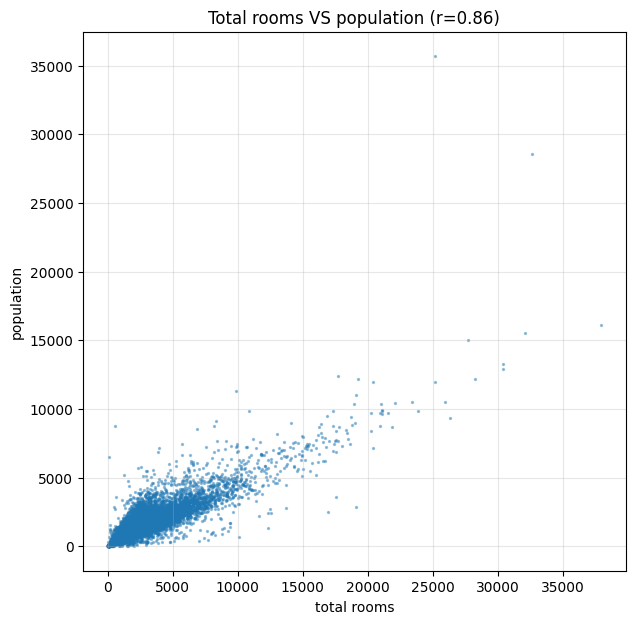

In [84]:
plt.figure(figsize=(7, 7))
plt.scatter(train_data['total_rooms'], train_data['population'], s=2, alpha=0.4)
correlation = train_data['population'].corr(train_data['total_rooms'])
plt.xlabel('total rooms')
plt.ylabel('population')
plt.title(f'Total rooms VS population (r={correlation:.2f})')
plt.grid(True, alpha=0.3)
plt.show()

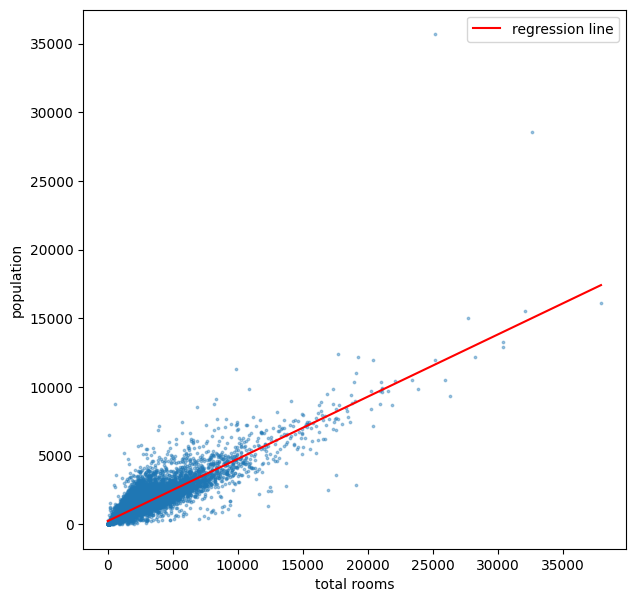

In [55]:
x = train_data['total_rooms']
y = train_data['population']
slope, intercept = np.polyfit(x, y, 1)
plt.figure(figsize=(7, 7))
plt.scatter(x, y, s=3, alpha=0.4)
xs = np.linspace(min(x), max(x), 100)
plt.plot(xs, slope * xs + intercept, color='red', label='regression line')
plt.legend()
plt.xlabel('total rooms')
plt.ylabel('population')
plt.show()

In [79]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17000 entries, 0 to 16999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           17000 non-null  float64
 1   latitude            17000 non-null  float64
 2   housing_median_age  17000 non-null  float64
 3   total_rooms         17000 non-null  float64
 4   total_bedrooms      17000 non-null  float64
 5   population          17000 non-null  float64
 6   households          17000 non-null  float64
 7   median_income       17000 non-null  float64
 8   median_house_value  17000 non-null  float64
dtypes: float64(9)
memory usage: 1.2 MB


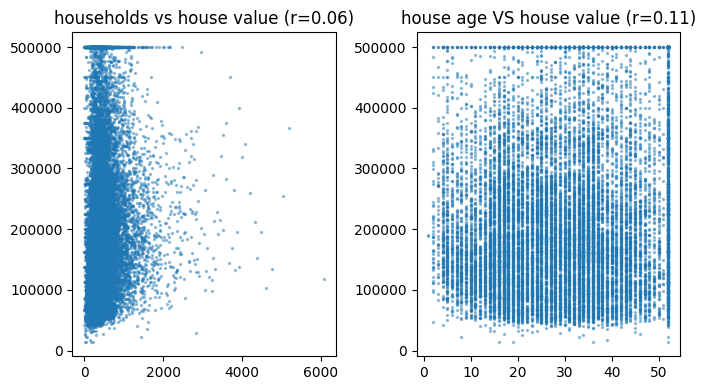

In [88]:
fig, plots = plt.subplots(nrows=1, ncols=2, figsize=(7, 4))

plots[0].scatter(train_data['households'], train_data['median_house_value'], s=2, alpha=0.4)
corr0 = train_data['households'].corr(train_data['median_house_value'])
plots[0].set_title(f'households vs house value (r={corr0:.2f})')

plots[1].scatter(train_data['housing_median_age'], train_data['median_house_value'], s=2, alpha=0.4)
corr1 = train_data['housing_median_age'].corr(train_data['median_house_value'])
plots[1].set_title(f'house age VS house value (r={corr1:.2f})')
plt.tight_layout()
plt.show()


# This is the main task of the excercise

## You need to implement the following functions which <br/> implements Linear Regression and all it's required functions

### The first major function is the 'predict' function <br/> Remember the Linear Regression equation is
$$\hat{Y} = w_0 + w_1 x_1 + w_2 x_2 + ... + w_m x_m$$

### hint: try to implement a 'vectorized' version by using a matrix multiplication<br/> which will massively increase performance

In [ ]:
 def predict(w, x):
    '''
    Return the linear regression prediction from the weights and input features
    Args:
        w: The weight vector, shape: (features, 1)
        x: The input data, shape: (num_samples, features)
    Returns:
        The prediction of the model, shape: (num_samples, 1)
    '''
    ### YOUR CODE HERE
    raise NotImplementedError

def init_weights(x):
    '''
    Initialize the weights vector, the data is passed in to know how many weights you need
    Args:
        x: The input data, shape: (num_samples, features)
    Returns:
        The initial weight vector of zeros, shape: (features, 1)
    '''
    ### YOUR CODE HERE
    raise NotImplementedError

### Next you have to implement the Mean Squared Error Loss calculation by applying the following formula
$$LOSS(W)=\frac{1}{2n} \sum_{i=1}^{n} (\hat{y}_i-y_i)^2$$

In [ ]:
def loss(y_hat, y):
    '''
    Calculate the Mean Squared Error based on the y_hat (the predicted value) and y (the true values)
    Args:
        y_hat: the predicted values of the input, shape: (num_samples, 1)
        y: the true values of the input, shape: (num_samples, 1)
    Returns:
        Mean Squared Error, shape: Scaler
    '''
    ### YOUR CODE HERE
    raise NotImplementedError

### Next you have to implement the gradient calculation for the weights accoarding to the formula

$$\frac{\partial LOSS(W)}{\partial W_j}
= \frac{\partial}{\partial W_j} \frac{1}{2n} \sum_{i=1}^{n} (\hat{y}_i-y_i)^2
= \frac{1}{2} \sum_{i=1}^{n} ((\hat{y}_i-y_i)*x_{i,j})$$

In [ ]:

def get_gradient(w, x, y_hat, y):
    '''
    Get the gradient of the weights using the parameters passed
    (Note: not all parameters passed have to be used)
    Args:
        w: The weight vector, shape: (features, 1)
        x: The input data, shape: (num_samples, features)
        y_hat: the predicted values of the input, shape: (num_samples, 1)
        y: the true values of the input, shape: (num_samples, 1)
    Returns:
        The gradients of the weight vector, shape: (features, 1)
    '''
    ### YOUR CODE HERE
    raise NotImplementedError

### Next you have to implement the gradient descent update for the weights according to the formula

$$w_j:=w_j - \alpha * \frac{\partial LOSS(W)}{\partial W_j} $$

In [ ]:
def get_updated_weights(w, w_gradients, learning_rate):
    '''
    Calculate the new value of the weights after applying the gradient descent weight update rule
    Args:
        w: The weight vector, shape: (features, 1)
        w_gradients: The gradients of the weight vector, shape: (features, 1)
        learning_rate: The learning rate of the algorithm, shape: Scaler
    Returns:
        The updated value of the weights, shape: (features, 1)
    '''
    ### YOUR CODE HERE
    raise NotImplementedError

### Finally implement the training loop, this should simply be<br/> a loop that calls the functions you implemented above

In [ ]:
def train(epochs, x, y, learning_rate=1e-3, initial_weights=None):
    '''
    The main train loop for the algorithm. This performs the gradient update step 'epochs' times.
    Args:
        x: The input data, shape: (num_samples, features)
        y: the true values of the input, shape: (num_samples, 1)
        learning_rate: The learning rate of the algorithm, shape: Scaler
        initial_weights: The initial weight to start training, this should be passed to continue training
    Returns:
        The final weight values after applying 'epochs' number of updates on 'initial_weights', shape: (features, 1)
    '''
    if initial_weights is None:
        weight = init_weights(x)
    else:
        weight = initial_weights

    for epoch in range(epochs):
        ### YOUR CODE HERE
        raise NotImplementedError


### The cell below will run your code

### After 200,000 epochs our results were the following:
### Train loss: 2.39e+08<br/> Valid loss: 3.65e+08<br/> Test loss: 3.60+08

In [ ]:
%%time
w = None
for i in range(20):
    w = train(10000, train_x, train_y, learning_rate=5e-3, initial_weights=w)
    print('epoch:', (i+1)*10000, end='   ')
    print('Train loss:', loss(predict(w, train_x), train_y), end='   ')
    print('Valid loss:', loss(predict(w, valid_x), valid_y))
print('Final Model -- Test loss:', loss(predict(w, test_x), test_y))